In [245]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import confusion_matrix
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


In [246]:
torch.manual_seed(42)

In [247]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [248]:

X_test = pd.read_csv('./DATASET/team10/task3/testing_data_set_10_data.csv', header=None)
y_test = pd.read_csv('./DATASET/team10/task3/testing_data_set_10_labels.csv', header=None)
X_train_L = pd.read_csv('./DATASET/team10/task3/training_data_set_10_labeled_data.csv', header=None)
y_train_L = pd.read_csv('./DATASET/team10/task3/training_data_set_10_labeled_labels.csv', header=None)
X_train_UL = pd.read_csv('./DATASET/team10/task3/training_data_set_10_unlabeled.csv', header=None)
X_val = pd.read_csv('./DATASET/team10/task3/validation_data_set_10_data.csv', header=None)
y_val = pd.read_csv('./DATASET/team10/task3/validation_data_set_10_labels.csv', header=None)

In [249]:
y_train_L

,0
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0
...,...
745,4.0
746,4.0
747,4.0
748,4.0


In [250]:

scaler = StandardScaler()

scaler.fit(X_train_UL)
X_train_UL = scaler.transform(X_train_UL)
X_train_L = scaler.transform(X_train_L)
X_test = scaler.transform(X_test)
X_val = scaler.transform(X_val)

In [251]:
X_test.shape, X_train_L.shape, X_train_UL.shape, X_val.shape, y_test.shape, y_train_L.shape, y_val.shape

((250, 36), (750, 36), (1750, 36), (250, 36), (250, 1), (750, 1), (250, 1))

In [252]:
class CustomDataset(Dataset):
    def __init__(self, features, labels=None, is_autoencoder=False):
        self.features = torch.tensor(features, dtype=torch.float32)
        self.is_autoencoder = is_autoencoder

        if labels is not None:
            if is_autoencoder:
                self.labels = torch.tensor(labels, dtype=torch.float32)
            else:
                self.labels = torch.tensor(labels, dtype=torch.long)
        else:
            self.labels= None

    def __len__(self):
        return len(self.features)
    
    def __getitem__(self, idx):
        if self.labels is not None:
            return self.features[idx], self.labels[idx]
        return self.features[idx]

In [253]:
print("X_train_L shape:", X_train_L.shape)
print("y_train_L shape:", y_test.shape)
print("X_train_UL shape:", X_train_UL.shape)

X_train_L shape: (750, 36)
y_train_L shape: (250, 1)
X_train_UL shape: (1750, 36)


In [254]:
train_dataset_L = CustomDataset(X_train_L, y_train_L.squeeze())
train_dataset_UL = CustomDataset(X_train_UL, X_train_UL, is_autoencoder=True)
test_dataset = CustomDataset(X_test, y_test.squeeze())
val_dataset = CustomDataset(X_val, y_val.squeeze())

In [255]:
train_L_loader= DataLoader(train_dataset_L, batch_size=32, shuffle=True, pin_memory=True)
train_loader_UL = DataLoader(train_dataset_UL, batch_size=32, shuffle=True, pin_memory=True)

test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, pin_memory=True)

In [256]:
def get_pca(features):
    pca_hidden = PCA(n_components=0.95)
    pca_hidden.fit(features)
    hidden_dim = pca_hidden.n_components_
    
    pca_bottleneck = PCA(n_components=0.90)
    pca_bottleneck.fit(features)
    bottleneck_dim = pca_bottleneck.n_components_
    return hidden_dim, bottleneck_dim

In [257]:
get_pca(X_train_UL)

(np.int64(31), np.int64(26))

In [258]:
class DFFNN(nn.Module):
    def __init__(self, i, h1, b1, h2, b2, h3, b3, op, pretrained=None):
        super().__init__()
        self.encoder_1 = nn.Sequential(
            nn.Linear(i, h1),
            nn.Tanh(),
            nn.Linear(h1, b1),
            nn.Tanh()
        )
        self.encoder_2 = nn.Sequential(
            nn.Linear(b1, h2),
            nn.Tanh(),
            nn.Linear(h2, b2),
            nn.Tanh()
        )
        self.encoder_3 = nn.Sequential(
            nn.Linear(b2, h3),
            nn.Tanh(),
            nn.Linear(h3, b3),
            nn.Tanh()
        )
        self.classifier = nn.Linear(b3, op)
        
        if pretrained is not None:
            ae_1, ae_2, ae_3 = pretrained
            self.encoder_1.load_state_dict(ae_1.encoder.state_dict())
            self.encoder_2.load_state_dict(ae_2.encoder.state_dict())
            self.encoder_3.load_state_dict(ae_3.encoder.state_dict())    
        
    def forward(self, x):
        x = self.encoder_1(x)
        x = self.encoder_2(x)
        x = self.encoder_3(x)
        return self.classifier(x)
        

In [259]:
class AutoEncoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, bottleneck):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, bottleneck),
            nn.Tanh()
        )
        self.decoder = nn.Sequential(
            nn.Linear(bottleneck, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, input_dim)
        )
    
    def forward(self, x):
        encode = self.encoder(x)
        decode = self.decoder(encode)
        return decode
    def encode(self, x):
        return self.encoder(x)
    

In [260]:
def train_DFFNN(model, loader, lr=1e-3, threshold=1e-5):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr= lr)
    epoch = 0
    avg_loss = 0.0
    avg_loss_list = []
    prev_loss = float('inf')
    print(f"--------------------- DFFNN model training ---------------------")
    model.train()
    while epoch < 10000:
        total_epoch_loss = 0.0
        for batch_features, batch_labels in loader:
            batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)
            optimizer.zero_grad()
            outputs = model(batch_features)
            loss = criterion(outputs, batch_labels)
            total_epoch_loss += loss.item() * batch_features.size(0)
            loss.backward()
            optimizer.step()
        avg_loss = total_epoch_loss / len(loader.dataset)
        avg_loss_list.append(avg_loss)
        print(f"Epoch: {epoch + 1}, Loss: {avg_loss}")
        if(abs(avg_loss - prev_loss) < threshold):
            print(f"Converged at epoch: {epoch+1}")
            break
        prev_loss = avg_loss
        epoch+=1
    return avg_loss_list

In [261]:
def pretrain_ae(model, loader, threshold=1e-5, lr=1e-3):
    model.to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    prev_loss = float('inf')
    epoch = 0
    print(f"-------------- pre training autoencoder --------------")
    model.train()
    while epoch < 10000:
        total_epoch_loss = 0.0
        for batch_features, batch_labels in loader:
            batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)
            optimizer.zero_grad()
            outputs = model(batch_features)
            loss = criterion(outputs, batch_labels)
            total_epoch_loss += loss.item() * batch_features.size(0)
            loss.backward()
            optimizer.step()
        avg_loss = total_epoch_loss / len(loader.dataset)
        print(f"Epoch: {epoch+1}, Loss: {avg_loss}")
        if abs(prev_loss - avg_loss) < threshold :
            print(f"Converged at Epoch: {epoch+1}")
            break
        prev_loss = avg_loss
        epoch+=1

In [262]:
def evaluate_model(model, loader, model_type="AE"):
    model.to(device)
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for batch_features, batch_labels in loader:
            batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)
            outputs = model(batch_features)
            _, preds = torch.max(outputs, 1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch_labels.cpu().numpy())
    
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(10,6))
    sns.heatmap(cm, annot=True, fmt='d')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix for {model_type}")
    plt.show()
    return cm    

In [263]:
def extract_latent(model, loader):
    model.to(device)
    model.eval()
    latent_vectors = []
    with torch.no_grad():
        for batch_features, _ in loader:
            batch_features = batch_features.to(device)
            encode = model.encode(batch_features)
            latent_vectors.append(encode.cpu())
    return torch.cat(latent_vectors, dim = 0)

Pre-Training

In [264]:
input_dim = X_train_UL.shape[1]
input_dim

36

AutoEncoder1

In [265]:
hidden_1, bottleneck_1 = get_pca(X_train_UL)
hidden_1, bottleneck_1

(np.int64(31), np.int64(26))

In [266]:
ae_1 = AutoEncoder(
    input_dim=input_dim,
    hidden_dim=hidden_1,
    bottleneck=bottleneck_1
)

In [267]:
pretrain_ae(
    ae_1,
    train_loader_UL,
    
)

-------------- pre training autoencoder --------------
Epoch: 1, Loss: 0.8962865579468864
Epoch: 2, Loss: 0.6854377354213169
Epoch: 3, Loss: 0.576153999056135
Epoch: 4, Loss: 0.4999414085320064
Epoch: 5, Loss: 0.4415157992839813
Epoch: 6, Loss: 0.3998939346245357
Epoch: 7, Loss: 0.36975605181285315
Epoch: 8, Loss: 0.34414199778011867
Epoch: 9, Loss: 0.3231825522354671
Epoch: 10, Loss: 0.3050266751391547
Epoch: 11, Loss: 0.2900280255249568
Epoch: 12, Loss: 0.2770886633566448
Epoch: 13, Loss: 0.2646422215359552
Epoch: 14, Loss: 0.25302488459859573
Epoch: 15, Loss: 0.24251404356956482
Epoch: 16, Loss: 0.23356315342017583
Epoch: 17, Loss: 0.2269018223115376
Epoch: 18, Loss: 0.22100008422987802
Epoch: 19, Loss: 0.21491939617906297
Epoch: 20, Loss: 0.20799573578153338
Epoch: 21, Loss: 0.19958384665421078
Epoch: 22, Loss: 0.19088433005128588
Epoch: 23, Loss: 0.1832603828225817
Epoch: 24, Loss: 0.17553945805345264
Epoch: 25, Loss: 0.16859845418589456
Epoch: 26, Loss: 0.16272043679441725
Epoch:

In [268]:
train_loader_UL_seq = DataLoader(train_dataset_UL, batch_size=32, shuffle=False, pin_memory=True)
encode_1 = extract_latent(ae_1, train_loader_UL_seq)
encode_1_np = encode_1.detach().numpy()

In [269]:
hidden_2, bottleneck_2 = get_pca(encode_1_np)
hidden_2, bottleneck_2

(np.int64(24), np.int64(23))

In [270]:
dataset_z1 = CustomDataset(
    encode_1_np,
    encode_1_np,
    is_autoencoder=True
)
loader_z1_seq = DataLoader(dataset_z1, shuffle=False, batch_size=32, pin_memory=True)

loader_z1 = DataLoader(
    dataset_z1,
    shuffle=True,
    batch_size=32,
    pin_memory=True
)

In [271]:
ae_2 = AutoEncoder(
    bottleneck_1,
    hidden_2,
    bottleneck_2
)
pretrain_ae(ae_2, loader_z1)

-------------- pre training autoencoder --------------
Epoch: 1, Loss: 0.0382489358655044
Epoch: 2, Loss: 0.029407045534678867
Epoch: 3, Loss: 0.024183787032961847
Epoch: 4, Loss: 0.02019894735302244
Epoch: 5, Loss: 0.01702149787758078
Epoch: 6, Loss: 0.01463795658307416
Epoch: 7, Loss: 0.013267592905887535
Epoch: 8, Loss: 0.01203354974836111
Epoch: 9, Loss: 0.010824548273214272
Epoch: 10, Loss: 0.010058760090598038
Epoch: 11, Loss: 0.009470048398843833
Epoch: 12, Loss: 0.00872078103785004
Epoch: 13, Loss: 0.008071369043418338
Epoch: 14, Loss: 0.007488187959151608
Epoch: 15, Loss: 0.006939716953784227
Epoch: 16, Loss: 0.006517340476491621
Epoch: 17, Loss: 0.006376909119210073
Epoch: 18, Loss: 0.0061287349909543995
Epoch: 19, Loss: 0.005582730503486735
Epoch: 20, Loss: 0.005312855882304055
Epoch: 21, Loss: 0.0052681142176900595
Epoch: 22, Loss: 0.005224671819912536
Epoch: 23, Loss: 0.005189888234649386
Epoch: 24, Loss: 0.005158308740705252
Epoch: 25, Loss: 0.005119514252990484
Epoch: 26

In [272]:

encode_2 = extract_latent(ae_2, loader_z1_seq)
encode_2_np = encode_2.detach().numpy()

In [273]:
hidden_3, bottleneck_3 = get_pca(encode_2_np)
hidden_3, bottleneck_3

(np.int64(20), np.int64(19))

In [274]:
dataset_z2 =  CustomDataset(
    encode_2_np,
    encode_2_np,
    is_autoencoder=True
)

loader_z2 = DataLoader(
    dataset_z2,
    shuffle=True,
    batch_size=32,
    pin_memory=True
)

In [275]:
ae_3 = AutoEncoder(bottleneck_2, hidden_3, bottleneck_3)
pretrain_ae(ae_3, loader_z2)

-------------- pre training autoencoder --------------
Epoch: 1, Loss: 0.04201708355545997
Epoch: 2, Loss: 0.03151280217511313
Epoch: 3, Loss: 0.02710885885783604
Epoch: 4, Loss: 0.0230290692618915
Epoch: 5, Loss: 0.01975643168389797
Epoch: 6, Loss: 0.017431149425251143
Epoch: 7, Loss: 0.015463731865797725
Epoch: 8, Loss: 0.013660938817475524
Epoch: 9, Loss: 0.012354383197213922
Epoch: 10, Loss: 0.011415069094726017
Epoch: 11, Loss: 0.010772140233644418
Epoch: 12, Loss: 0.0100416986984866
Epoch: 13, Loss: 0.009444343058126314
Epoch: 14, Loss: 0.009083127093102251
Epoch: 15, Loss: 0.008583781954965421
Epoch: 16, Loss: 0.008023191039051329
Epoch: 17, Loss: 0.007777044154171433
Epoch: 18, Loss: 0.007649340617869581
Epoch: 19, Loss: 0.007541256033416305
Epoch: 20, Loss: 0.007441156833299569
Epoch: 21, Loss: 0.007354386486645255
Epoch: 22, Loss: 0.007246913908847741
Epoch: 23, Loss: 0.007107137227164847
Epoch: 24, Loss: 0.006880848222545215
Epoch: 25, Loss: 0.006361653387546539
Epoch: 26, L

In [276]:
# input_dim already defined
num_classes = len(y_train_L.iloc[:,0].unique())
num_classes

5

DFFNN USING ONLY LABELLED DATA

In [277]:
DFFNN_A = DFFNN(
    input_dim,
    hidden_1,
    bottleneck_1,
    hidden_2,
    bottleneck_2,
    hidden_3,
    bottleneck_3,
    num_classes
)

In [278]:
avg_loss_a = train_DFFNN(DFFNN_A, train_L_loader)

--------------------- DFFNN model training ---------------------
Epoch: 1, Loss: 1.6065339024861653
Epoch: 2, Loss: 1.5837644510269164
Epoch: 3, Loss: 1.5487100365956625
Epoch: 4, Loss: 1.5115590365727742
Epoch: 5, Loss: 1.4899134972890218
Epoch: 6, Loss: 1.4687658020655314
Epoch: 7, Loss: 1.4472795324325562
Epoch: 8, Loss: 1.4265161301294962
Epoch: 9, Loss: 1.405444727261861
Epoch: 10, Loss: 1.3878334341049194
Epoch: 11, Loss: 1.3720692780812582
Epoch: 12, Loss: 1.3512054030100504
Epoch: 13, Loss: 1.3344777790705362
Epoch: 14, Loss: 1.3149388297398885
Epoch: 15, Loss: 1.3059190409978232
Epoch: 16, Loss: 1.2854918375015258
Epoch: 17, Loss: 1.2715277516047159
Epoch: 18, Loss: 1.2569494091669717
Epoch: 19, Loss: 1.2462463162740072
Epoch: 20, Loss: 1.2345309956868489
Epoch: 21, Loss: 1.2214141931533813
Epoch: 22, Loss: 1.2159981104532878
Epoch: 23, Loss: 1.208271808942159
Epoch: 24, Loss: 1.1946343399683634
Epoch: 25, Loss: 1.1901043548583985
Epoch: 26, Loss: 1.1703574390411378
Epoch: 27,

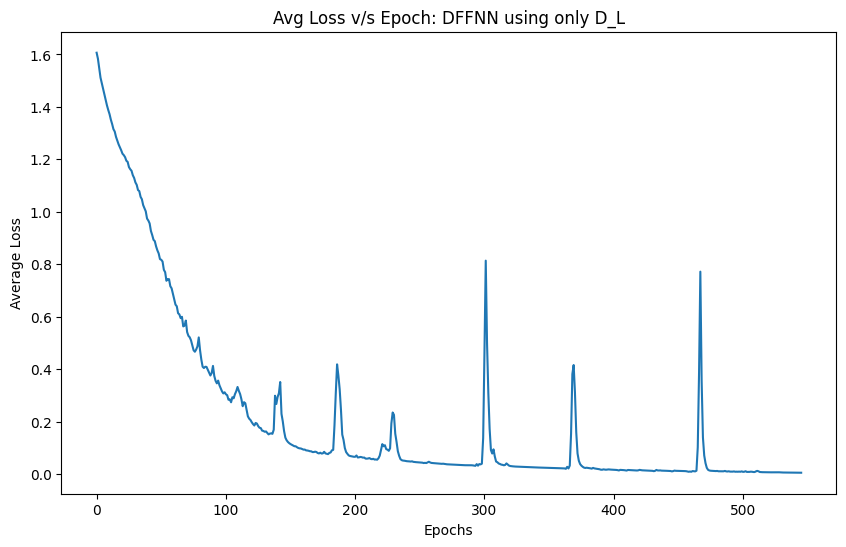

In [279]:
plt.figure(figsize=(10,6))
plt.plot(avg_loss_a)
plt.xlabel("Epochs")
plt.ylabel("Average Loss")
plt.title("Avg Loss v/s Epoch: DFFNN using only D_L")
plt.show()

In [280]:
def confm(test_data_t,test_label_t,model,title,type):
    model.to(device)
    test_data_t,test_label_t = test_data_t.to(device), test_label_t.to(device)
    model.eval()
    with torch.no_grad():
        outputs = model(test_data_t)
        preds = torch.argmax(outputs, dim=1)

    cm = confusion_matrix(test_label_t, preds)
    plt.figure(figsize=(10,5))
    sns.heatmap(cm, annot=True, fmt="d")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f'Confusion Matrix for {title} data for {type}')
    plt.show()

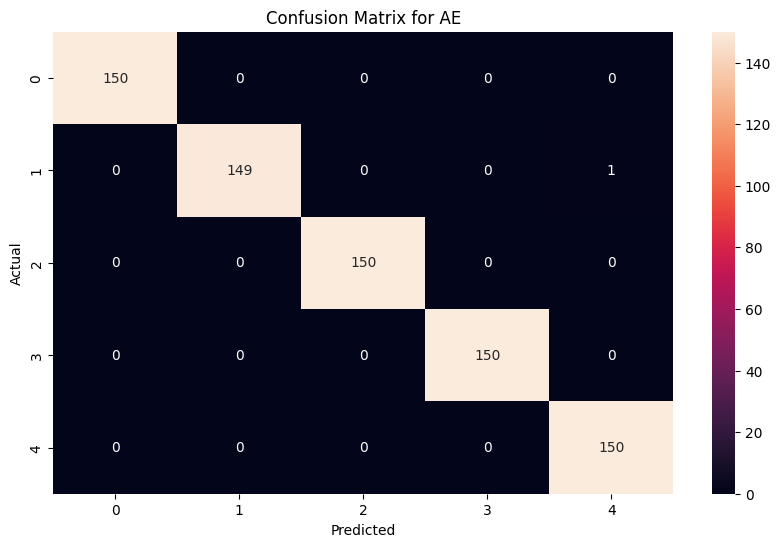

array([[150,   0,   0,   0,   0],
       [  0, 149,   0,   0,   1],
       [  0,   0, 150,   0,   0],
       [  0,   0,   0, 150,   0],
       [  0,   0,   0,   0, 150]])

In [281]:
evaluate_model(DFFNN_A, train_L_loader)

USING PRETRAINED AUTOENCODER

In [282]:
DFFNN_B = DFFNN(
    input_dim,
    hidden_1,
    bottleneck_1,
    hidden_2,
    bottleneck_2,
    hidden_3,
    bottleneck_3,
    num_classes,
    pretrained=(ae_1,ae_2,ae_3)
)

In [283]:
avg_loss_b = train_DFFNN(DFFNN_B, train_L_loader)

--------------------- DFFNN model training ---------------------
Epoch: 1, Loss: 1.5821498794555664
Epoch: 2, Loss: 1.501716757774353
Epoch: 3, Loss: 1.4433724374771117
Epoch: 4, Loss: 1.3926654036839803
Epoch: 5, Loss: 1.35479079691569
Epoch: 6, Loss: 1.3320041707356771
Epoch: 7, Loss: 1.321903610865275
Epoch: 8, Loss: 1.302547115643819
Epoch: 9, Loss: 1.2938565642038982
Epoch: 10, Loss: 1.2926923240025838
Epoch: 11, Loss: 1.2813496888478597
Epoch: 12, Loss: 1.2718218933741252
Epoch: 13, Loss: 1.2632138792673746
Epoch: 14, Loss: 1.261732839902242
Epoch: 15, Loss: 1.2508312962849935
Epoch: 16, Loss: 1.251698623339335
Epoch: 17, Loss: 1.2488169298171996
Epoch: 18, Loss: 1.2352698974609375
Epoch: 19, Loss: 1.2276217800776164
Epoch: 20, Loss: 1.2201745506922403
Epoch: 21, Loss: 1.2138504927953084
Epoch: 22, Loss: 1.2090608984629314
Epoch: 23, Loss: 1.2069841883977255
Epoch: 24, Loss: 1.2004940001169842
Epoch: 25, Loss: 1.186149230003357
Epoch: 26, Loss: 1.1812339153289795
Epoch: 27, Loss:

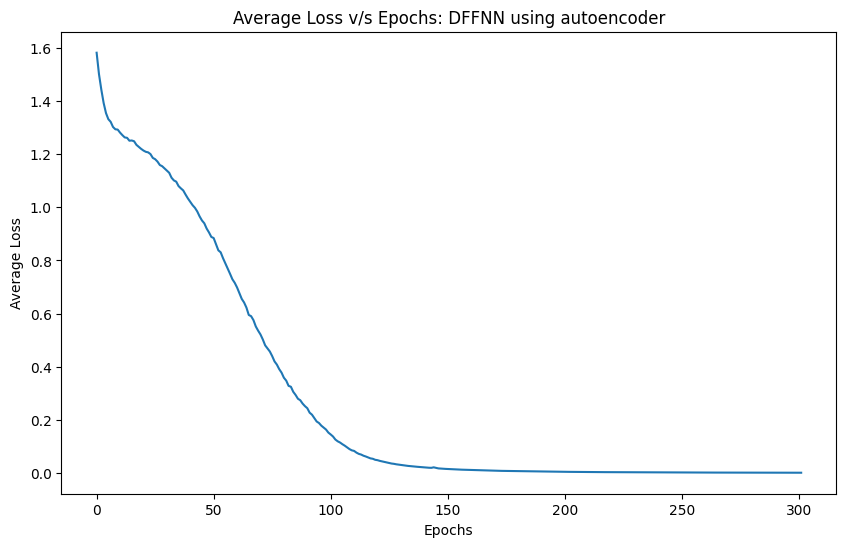

In [284]:
plt.figure(figsize=(10,6))
plt.plot(avg_loss_b)
plt.xlabel("Epochs")
plt.ylabel("Average Loss")
plt.title("Average Loss v/s Epochs: DFFNN using autoencoder")
plt.show()

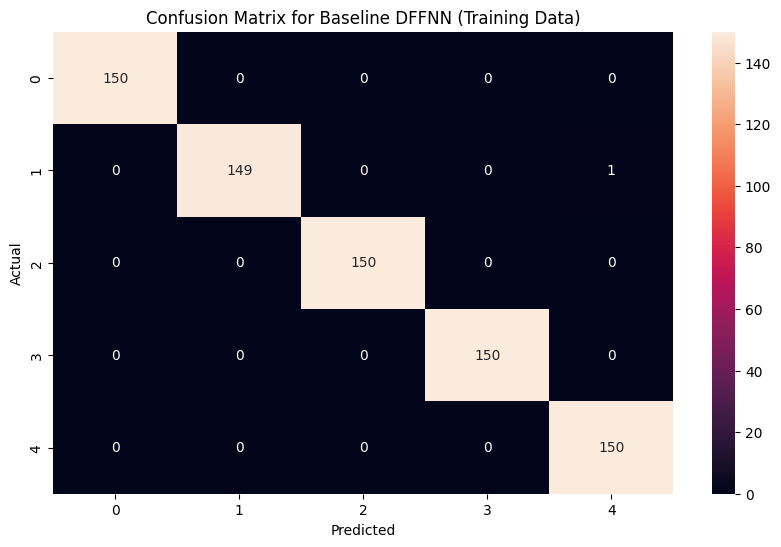

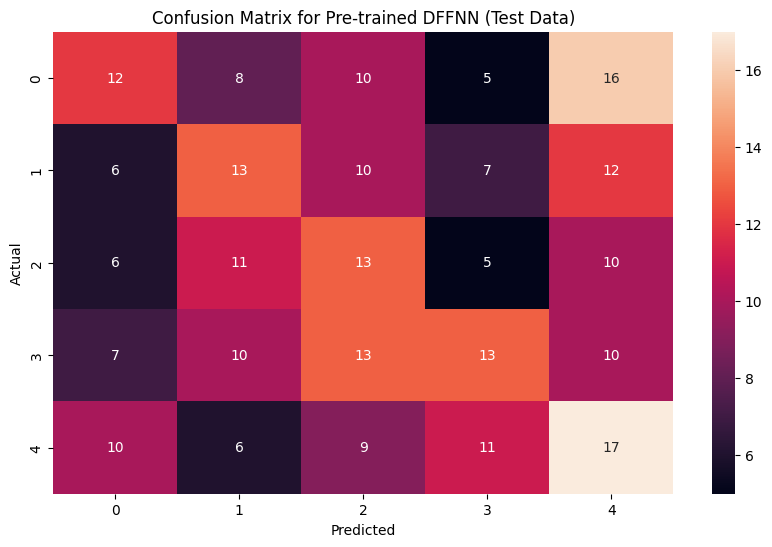

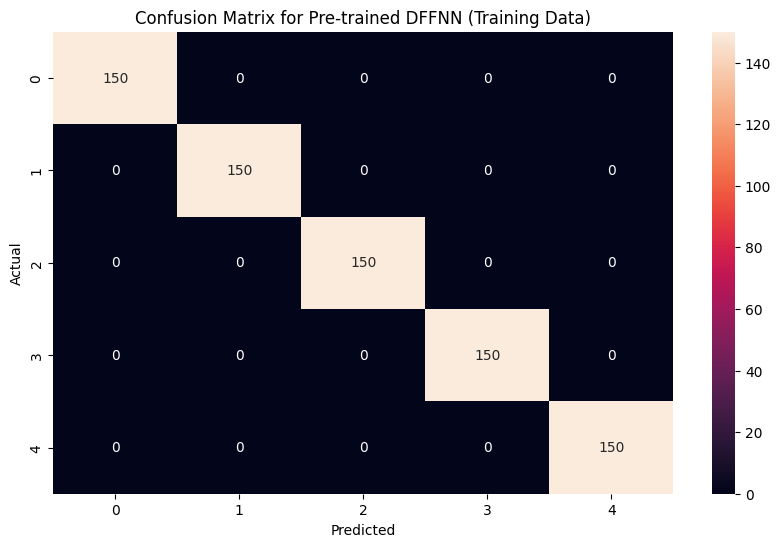

array([[150,   0,   0,   0,   0],
       [  0, 150,   0,   0,   0],
       [  0,   0, 150,   0,   0],
       [  0,   0,   0, 150,   0],
       [  0,   0,   0,   0, 150]])

In [289]:
evaluate_model(DFFNN_A, train_L_loader, model_type="Baseline DFFNN (Training Data)")
evaluate_model(DFFNN_B, test_loader, model_type="Pre-trained DFFNN (Test Data)")
evaluate_model(DFFNN_B, train_L_loader, model_type="Pre-trained DFFNN (Training Data)")